---
title: "Chapter 7: The Unit Circle: Sine and Cosine Functions"
subtitle: Notes drawn from OpenStax *Algebra and Trigonometry 2e* (§7.1–7.4) and *Precalculus 2e*
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
    "legend.frameon": True, "legend.facecolor": "#fcfcfb", "legend.edgecolor": "none", "legend.framealpha": 0.92, "figure.dpi": 110,
})

def setup(ax, xlim, ylim, title=None, ticks=1):
    """Axes through the origin, light grid, square units."""
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    for s in ("left", "bottom"):
        ax.spines[s].set_position("zero"); ax.spines[s].set_color(INK2)
    for s in ("right", "top"):
        ax.spines[s].set_visible(False)
    ax.set_xticks(np.arange(np.ceil(xlim[0]), xlim[1] + 0.01, ticks))
    ax.set_yticks(np.arange(np.ceil(ylim[0]), ylim[1] + 0.01, ticks))
    ax.tick_params(labelsize=8)
    ax.grid(color="#e6e5e0", linewidth=0.6); ax.set_axisbelow(True)
    ax.set_aspect("equal")
    if title: ax.set_title(title)

def dot(ax, x, y, filled=True, color=BLUE):
    ax.plot(x, y, "o", ms=7, color=color,
            mfc=color if filled else "#fcfcfb", mew=2, zorder=5)

In [2]:
from matplotlib.patches import Arc, Wedge, Polygon

def data_axes(ax, title=None, xlabel=None, ylabel=None):
    for s in ("right", "top"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(INK2)
    ax.grid(color="#e6e5e0", linewidth=0.6); ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    if title: ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel, fontsize=9, color=INK2)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9, color=INK2)

def clip(y, lim):
    y = np.asarray(y, dtype=float).copy(); y[np.abs(y) > lim] = np.nan; return y

def bare(ax, lim=1.4, title=None):
    """Clean axes for geometry pictures."""
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
    ax.axhline(0, color=INK2, lw=0.8); ax.axvline(0, color=INK2, lw=0.8)
    if title: ax.set_title(title)

def angle_arc(ax, theta_deg, r=0.35, color=ORANGE, start=0):
    """Arrowed arc from start to theta (degrees), counterclockwise if positive."""
    t = np.radians(np.linspace(start, theta_deg, 200))
    ax.plot(r*np.cos(t), r*np.sin(t), color=color, lw=1.6)
    ax.annotate("", xy=(r*np.cos(t[-1]), r*np.sin(t[-1])), xytext=(r*np.cos(t[-6]), r*np.sin(t[-6])),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

(sec-7-1)=
## 7.1 Angles

### Standard position

- An angle in **standard position** has its vertex at the origin and its **initial side** on the positive $x$-axis. The **terminal side** is where the rotation stops.
- **Positive** angles rotate counterclockwise; **negative** angles rotate clockwise.
- An angle whose terminal side lies on an axis ($0°, 90°, 180°, 270°$) is a **quadrantal angle**.
- **Coterminal** angles share a terminal side. They differ by a whole number of full turns: $\theta + 360°k$ or $\theta + 2\pi k$.

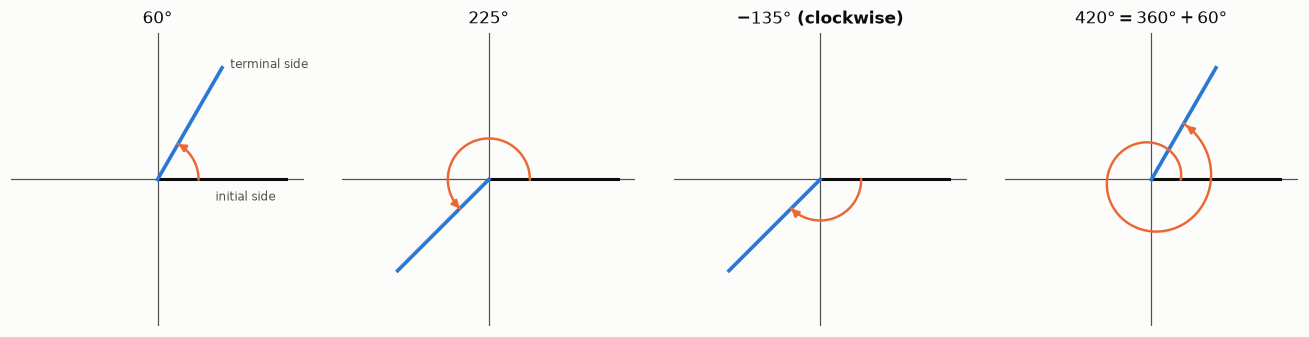

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, (deg, title) in zip(axes, [(60, "$60°$"), (225, "$225°$"), (-135, "$-135°$ (clockwise)"), (420, "$420° = 360° + 60°$")]):
    bare(ax, 1.25, title)
    ax.plot([0, 1.1], [0, 0], color=INK, lw=2)
    t = np.radians(deg); ax.plot([0, 1.1*np.cos(t)], [0, 1.1*np.sin(t)], color=BLUE, lw=2.4)
    if deg == 420:
        tt = np.radians(np.linspace(0, 420, 400)); rr = np.linspace(0.25, 0.55, 400)
        ax.plot(rr*np.cos(tt), rr*np.sin(tt), color=ORANGE, lw=1.6)
        ax.annotate("", xy=(rr[-1]*np.cos(tt[-1]), rr[-1]*np.sin(tt[-1])),
                    xytext=(rr[-8]*np.cos(tt[-8]), rr[-8]*np.sin(tt[-8])), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.6))
    else:
        angle_arc(ax, deg, r=0.35)
axes[0].text(0.75, -0.18, "initial side", fontsize=8, color=INK2, ha="center")
axes[0].text(0.62, 0.95, "terminal side", fontsize=8, color=INK2)
plt.tight_layout(); plt.show()

### Radians

An angle of **1 radian** cuts off an arc equal in length to the radius. In general,

$$
\theta = \frac{s}{r} \ \text{radians}, \qquad \text{one full turn} = \frac{2\pi r}{r} = 2\pi \ \text{rad} = 360°.
$$

| Convert | Multiply by |
|---|---|
| degrees → radians | $\dfrac{\pi}{180°}$ |
| radians → degrees | $\dfrac{180°}{\pi}$ |

| Degrees | $0°$ | $30°$ | $45°$ | $60°$ | $90°$ | $120°$ | $135°$ | $150°$ | $180°$ | $270°$ | $360°$ |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Radians | $0$ | $\dfrac{\pi}{6}$ | $\dfrac{\pi}{4}$ | $\dfrac{\pi}{3}$ | $\dfrac{\pi}{2}$ | $\dfrac{2\pi}{3}$ | $\dfrac{3\pi}{4}$ | $\dfrac{5\pi}{6}$ | $\pi$ | $\dfrac{3\pi}{2}$ | $2\pi$ |

**Worked examples.**

$$
\begin{aligned}
225° \cdot \frac{\pi}{180°} &= \frac{5\pi}{4}, \qquad
\frac{5\pi}{6} \cdot \frac{180°}{\pi} = 150°, \qquad
1 \text{ rad} = \frac{180°}{\pi} \approx 57.3° \\
800° - 2(360°) &= 80° \quad \text{(coterminal angle in } [0°, 360°)\text{)} \\
-\frac{19\pi}{4} + 3(2\pi) &= -\frac{19\pi}{4} + \frac{24\pi}{4} = \frac{5\pi}{4} \quad \text{(coterminal angle in } [0, 2\pi)\text{)}
\end{aligned}
$$

### Arc length, sector area, and speed

With $\theta$ **in radians**:

| Quantity | Formula |
|---|---|
| Arc length | $s = r\theta$ |
| Sector area | $A = \tfrac{1}{2}r^2\theta$ |
| Angular speed | $\omega = \dfrac{\theta}{t}$ |
| Linear speed | $v = \dfrac{s}{t} = r\omega$ |

**Worked example.** Radius 10 cm, central angle $120° = \dfrac{2\pi}{3}$:

$$
s = 10 \cdot \frac{2\pi}{3} = \frac{20\pi}{3} \approx 20.94 \text{ cm}, \qquad
A = \frac{1}{2}(10)^2 \cdot \frac{2\pi}{3} = \frac{100\pi}{3} \approx 104.72 \text{ cm}^2
$$

**Worked example (speed).** A wheel of radius 0.35 m turns at 300 revolutions per minute. Each revolution is $2\pi$ rad, so $\omega = 600\pi$ rad/min and

$$
v = r\omega = 0.35 \cdot 600\pi = 210\pi \approx 659.7 \text{ m/min} \approx 39.6 \text{ km/h}.
$$

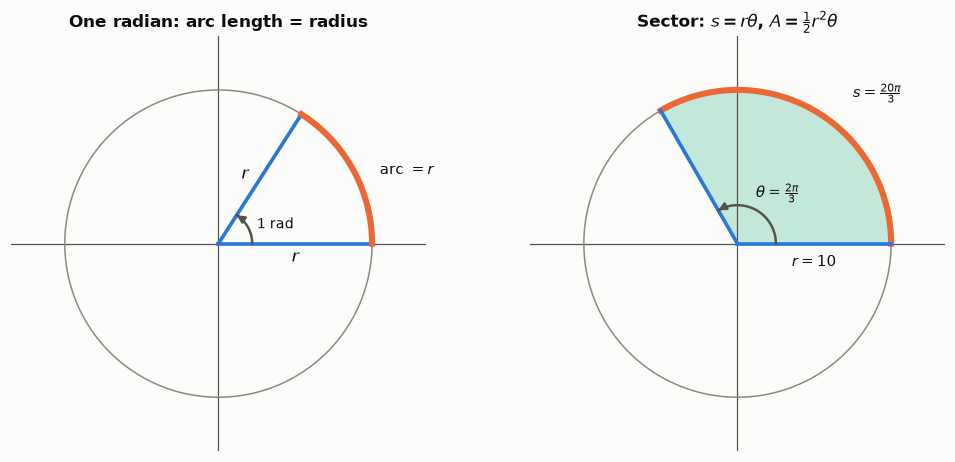

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.3))
ax = axes[0]; bare(ax, 1.35, "One radian: arc length = radius")
t = np.linspace(0, 2*np.pi, 300); ax.plot(np.cos(t), np.sin(t), color=GRAY, lw=1)
ax.plot([0, 1], [0, 0], color=BLUE, lw=2.4); ax.plot([0, np.cos(1)], [0, np.sin(1)], color=BLUE, lw=2.4)
ta = np.linspace(0, 1, 100); ax.plot(np.cos(ta), np.sin(ta), color=ORANGE, lw=4)
ax.text(0.5, -0.12, "$r$", ha="center", fontsize=11); ax.text(0.15, 0.42, "$r$", fontsize=11)
ax.text(1.05, 0.45, "arc $= r$", fontsize=10); angle_arc(ax, np.degrees(1), r=0.22, color=INK2)
ax.text(0.25, 0.1, "1 rad", fontsize=9)

ax = axes[1]; bare(ax, 1.35, r"Sector: $s = r\theta$, $A = \frac{1}{2}r^2\theta$")
ax.add_patch(Wedge((0, 0), 1, 0, 120, color=AQUA, alpha=0.25, lw=0))
ax.plot(np.cos(t), np.sin(t), color=GRAY, lw=1)
ta = np.linspace(0, 2*np.pi/3, 100); ax.plot(np.cos(ta), np.sin(ta), color=ORANGE, lw=4)
ax.plot([0, 1], [0, 0], color=BLUE, lw=2.4); ax.plot([0, np.cos(2*np.pi/3)], [0, np.sin(2*np.pi/3)], color=BLUE, lw=2.4)
angle_arc(ax, 120, r=0.25, color=INK2); ax.text(0.12, 0.3, r"$\theta = \frac{2\pi}{3}$", fontsize=10)
ax.text(0.75, 0.95, r"$s = \frac{20\pi}{3}$", fontsize=10); ax.text(0.5, -0.15, "$r = 10$", ha="center", fontsize=10)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Using degrees in $s = r\theta$ or $A = \tfrac{1}{2}r^2\theta$. Both formulas need radians.
- Converting with the fraction upside down. Units should cancel: degrees $\times \dfrac{\pi}{180°}$ leaves radians.
- Treating "radians" as having a degree symbol, or writing $\pi$ = 180. $\pi$ is a number ($\approx 3.14$); $\pi$ **radians** equals $180°$.
- Finding a coterminal angle by adding $180°$. Coterminal means whole turns: $360°$ or $2\pi$.
- Using revolutions per minute as $\omega$ directly. Multiply by $2\pi$ to get radians per minute.
:::

:::{important} The book underplays this
Radians aren't just another unit; they're the unit that makes calculus work. Facts like $\sin x \approx x$ for small $x$ and $\dfrac{d}{dx}\sin x = \cos x$ are true only in radians (in degrees, an extra factor of $\tfrac{\pi}{180}$ appears everywhere). Stewart, NumPy (`np.sin`), and R all assume radians. Use `np.radians` / `np.degrees` to convert.
:::

:::{tip} Where this shows up
Circular statistics: an animal's movement heading, or the time of day a camera trap fires, is an angle. Times are converted to radians ($2\pi \cdot \text{hour} / 24$) before estimating diel activity patterns and overlap between species. Arc length shows up in great-circle distances between GPS fixes.
:::

(sec-7-2)=
## 7.2 Right Triangle Trigonometry

### The six ratios

For an acute angle $\theta$ in a right triangle, label the sides **relative to $\theta$**:

| Function | Ratio | Reciprocal of |
|---|---|---|
| $\sin\theta$ | $\dfrac{\text{opposite}}{\text{hypotenuse}}$ | |
| $\cos\theta$ | $\dfrac{\text{adjacent}}{\text{hypotenuse}}$ | |
| $\tan\theta$ | $\dfrac{\text{opposite}}{\text{adjacent}}$ | |
| $\csc\theta$ | $\dfrac{\text{hypotenuse}}{\text{opposite}}$ | $\sin\theta$ |
| $\sec\theta$ | $\dfrac{\text{hypotenuse}}{\text{adjacent}}$ | $\cos\theta$ |
| $\cot\theta$ | $\dfrac{\text{adjacent}}{\text{opposite}}$ | $\tan\theta$ |

Mnemonic: **SOH CAH TOA**. Note that $\tan\theta = \dfrac{\sin\theta}{\cos\theta}$.

### Special angles

From the 30-60-90 triangle (sides $1, \sqrt{3}, 2$) and the 45-45-90 triangle (sides $1, 1, \sqrt{2}$):

| $\theta$ | $\sin\theta$ | $\cos\theta$ | $\tan\theta$ |
|---|---|---|---|
| $30° = \dfrac{\pi}{6}$ | $\dfrac{1}{2}$ | $\dfrac{\sqrt{3}}{2}$ | $\dfrac{\sqrt{3}}{3}$ |
| $45° = \dfrac{\pi}{4}$ | $\dfrac{\sqrt{2}}{2}$ | $\dfrac{\sqrt{2}}{2}$ | $1$ |
| $60° = \dfrac{\pi}{3}$ | $\dfrac{\sqrt{3}}{2}$ | $\dfrac{1}{2}$ | $\sqrt{3}$ |

The sine column reads $\dfrac{\sqrt{1}}{2}, \dfrac{\sqrt{2}}{2}, \dfrac{\sqrt{3}}{2}$; the cosine column is the same list reversed.

### Cofunction identities

The two acute angles of a right triangle are complementary, and one's "opposite" is the other's "adjacent":

$$
\sin\theta = \cos(90° - \theta), \qquad \tan\theta = \cot(90° - \theta), \qquad \sec\theta = \csc(90° - \theta).
$$

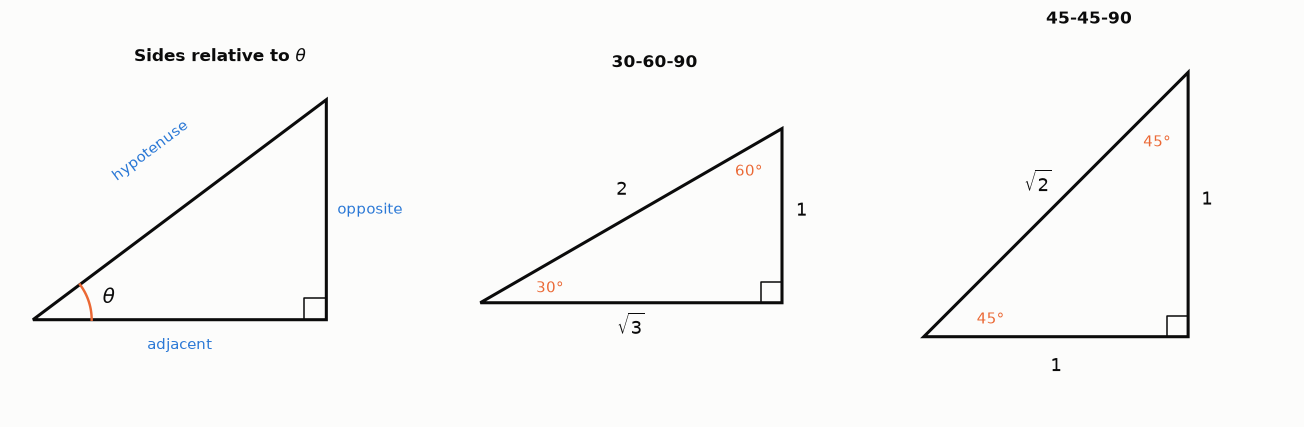

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
ax = axes[0]; ax.set_aspect("equal"); ax.axis("off"); ax.set_title(r"Sides relative to $\theta$")
ax.add_patch(Polygon([[0, 0], [4, 0], [4, 3]], closed=True, fill=False, ec=INK, lw=2))
ax.plot([3.7, 3.7, 4], [0, 0.3, 0.3], color=INK, lw=1)
t = np.linspace(0, np.arctan(3/4), 50); ax.plot(0.8*np.cos(t), 0.8*np.sin(t), color=ORANGE, lw=1.6)
ax.text(0.95, 0.22, r"$\theta$", fontsize=13)
ax.text(2.0, -0.4, "adjacent", ha="center", fontsize=10, color=BLUE)
ax.text(4.15, 1.5, "opposite", fontsize=10, color=BLUE, va="center")
ax.text(1.6, 1.9, "hypotenuse", fontsize=10, color=BLUE, rotation=36.87, ha="center")
ax.set_xlim(-0.3, 5.4); ax.set_ylim(-0.8, 3.4)

ax = axes[1]; ax.set_aspect("equal"); ax.axis("off"); ax.set_title("30-60-90")
s3 = np.sqrt(3)
ax.add_patch(Polygon([[0, 0], [s3, 0], [s3, 1]], closed=True, fill=False, ec=INK, lw=2))
ax.plot([s3 - 0.12, s3 - 0.12, s3], [0, 0.12, 0.12], color=INK, lw=1)
ax.text(s3/2, -0.18, r"$\sqrt{3}$", ha="center", fontsize=12); ax.text(s3 + 0.08, 0.5, "1", fontsize=12)
ax.text(0.78, 0.62, "2", fontsize=12); ax.text(0.32, 0.06, "30°", fontsize=10, color=ORANGE)
ax.text(s3 - 0.27, 0.73, "60°", fontsize=10, color=ORANGE)
ax.set_xlim(-0.2, 2.2); ax.set_ylim(-0.4, 1.3)

ax = axes[2]; ax.set_aspect("equal"); ax.axis("off"); ax.set_title("45-45-90")
ax.add_patch(Polygon([[0, 0], [1, 0], [1, 1]], closed=True, fill=False, ec=INK, lw=2))
ax.plot([0.92, 0.92, 1], [0, 0.08, 0.08], color=INK, lw=1)
ax.text(0.5, -0.13, "1", ha="center", fontsize=12); ax.text(1.05, 0.5, "1", fontsize=12)
ax.text(0.38, 0.55, r"$\sqrt{2}$", fontsize=12); ax.text(0.2, 0.05, "45°", fontsize=10, color=ORANGE)
ax.text(0.83, 0.72, "45°", fontsize=10, color=ORANGE)
ax.set_xlim(-0.15, 1.4); ax.set_ylim(-0.3, 1.15)
plt.tight_layout(); plt.show()

### Solving right triangles

Pick the function that links the side you know to the side you want, relative to the known angle.

**Worked example.** Hypotenuse 12, one acute angle $35°$:

$$
\text{opposite} = 12\sin 35° \approx 6.883, \qquad \text{adjacent} = 12\cos 35° \approx 9.830, \qquad \text{other angle} = 55°.
$$

**Worked example (tree height).** Standing 30 m from a tree on level ground, you sight the top at an angle of elevation of $52°$, with your eye 1.6 m above the ground:

$$
h = 30\tan 52° + 1.6 \approx 38.40 + 1.6 = 40.0 \text{ m}.
$$

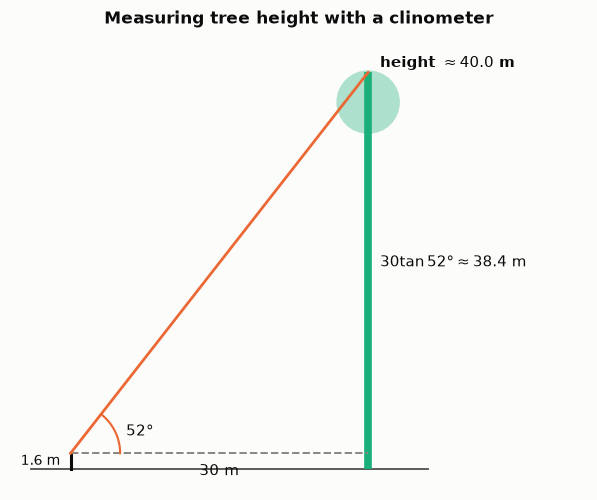

In [6]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.set_aspect("equal"); ax.axis("off"); ax.set_title("Measuring tree height with a clinometer")
d, eye, ang = 30, 1.6, np.radians(52); top = eye + d*np.tan(ang)
ax.plot([-4, 36], [0, 0], color=INK2, lw=1.2)
ax.plot([d, d], [0, top], color=AQUA, lw=5, solid_capstyle="butt")
ax.add_patch(plt.Circle((d, top - 3), 3.2, color=AQUA, alpha=0.35, lw=0))
ax.plot([0, 0], [0, eye], color=INK, lw=2)
ax.plot([0, d], [eye, eye], color=GRAY, ls="--", lw=1.3)
ax.plot([0, d], [eye, top], color=ORANGE, lw=1.8)
t = np.linspace(0, ang, 50); ax.plot(5*np.cos(t), eye + 5*np.sin(t), color=ORANGE, lw=1.4)
ax.text(5.6, eye + 1.8, "52°", fontsize=10)
ax.text(d/2, eye - 2.2, "30 m", ha="center", fontsize=10)
ax.text(d + 1.2, (eye + top)/2, r"$30\tan 52° \approx 38.4$ m", fontsize=10, va="center")
ax.text(-1, eye/2, "1.6 m", ha="right", fontsize=9, va="center")
ax.text(d + 1.2, top + 0.5, f"height $\\approx {top:.1f}$ m", fontsize=10, fontweight="bold")
ax.set_xlim(-6, 52); ax.set_ylim(-2, top + 4)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Labeling "opposite" and "adjacent" without reference to the angle. They swap when you switch to the other acute angle.
- Calculator in the wrong mode. $\sin 30 \approx -0.988$ in radian mode. Check the mode, or in Python convert with `np.radians(30)` first.
- Using the hypotenuse as a leg. The hypotenuse is always opposite the right angle and is the longest side.
- Forgetting eye height (or instrument height) in elevation problems.
:::

:::{tip} Where this shows up
Clinometer tree heights are exactly this calculation. On sloped plots, field crews convert slope distance to horizontal distance with $d_h = d_s\cos\theta$, so a fixed-radius plot covers the right map area. Vector components (wind, current, an animal's step split into east and north movement) are $r\cos\theta$ and $r\sin\theta$.
:::

(sec-7-3)=
## 7.3 Unit Circle

### Sine and cosine for any angle

The **unit circle** is $x^2 + y^2 = 1$. For any real number $t$, go a distance $t$ counterclockwise around the circle from $(1, 0)$ (clockwise if $t < 0$) and call the endpoint $(x, y)$. Then

$$
\cos t = x, \qquad \sin t = y.
$$

This extends sine and cosine from acute angles to **every real number**. On a circle of radius $r$, the point at angle $t$ is $(r\cos t,\ r\sin t)$.

| Property | Sine and cosine |
|---|---|
| Domain | $(-\infty, \infty)$ |
| Range | $[-1, 1]$ |
| Pythagorean Identity | $\cos^2 t + \sin^2 t = 1$ |

### Signs by quadrant

| Quadrant | $\cos t$ ($x$) | $\sin t$ ($y$) | Positive functions |
|---|---|---|---|
| I | $+$ | $+$ | all |
| II | $-$ | $+$ | sine (and csc) |
| III | $-$ | $-$ | tangent (and cot) |
| IV | $+$ | $-$ | cosine (and sec) |

Mnemonic for quadrants I–IV: **A**ll **S**tudents **T**ake **C**alculus.

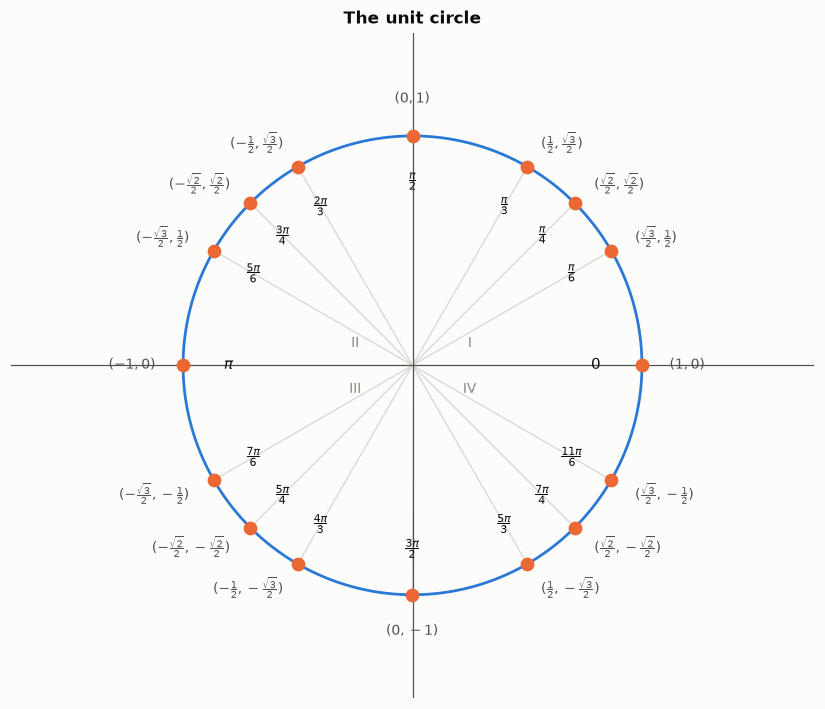

In [7]:
fig, ax = plt.subplots(figsize=(7.6, 7.6))
bare(ax, 1.55, "The unit circle")
t = np.linspace(0, 2*np.pi, 400); ax.plot(np.cos(t), np.sin(t), color=BLUE, lw=1.8)
lab = {0: (r"$0$", r"$(1, 0)$"), 30: (r"$\frac{\pi}{6}$", r"$(\frac{\sqrt{3}}{2}, \frac{1}{2})$"),
       45: (r"$\frac{\pi}{4}$", r"$(\frac{\sqrt{2}}{2}, \frac{\sqrt{2}}{2})$"), 60: (r"$\frac{\pi}{3}$", r"$(\frac{1}{2}, \frac{\sqrt{3}}{2})$"),
       90: (r"$\frac{\pi}{2}$", r"$(0, 1)$"), 120: (r"$\frac{2\pi}{3}$", r"$(-\frac{1}{2}, \frac{\sqrt{3}}{2})$"),
       135: (r"$\frac{3\pi}{4}$", r"$(-\frac{\sqrt{2}}{2}, \frac{\sqrt{2}}{2})$"), 150: (r"$\frac{5\pi}{6}$", r"$(-\frac{\sqrt{3}}{2}, \frac{1}{2})$"),
       180: (r"$\pi$", r"$(-1, 0)$"), 210: (r"$\frac{7\pi}{6}$", r"$(-\frac{\sqrt{3}}{2}, -\frac{1}{2})$"),
       225: (r"$\frac{5\pi}{4}$", r"$(-\frac{\sqrt{2}}{2}, -\frac{\sqrt{2}}{2})$"), 240: (r"$\frac{4\pi}{3}$", r"$(-\frac{1}{2}, -\frac{\sqrt{3}}{2})$"),
       270: (r"$\frac{3\pi}{2}$", r"$(0, -1)$"), 300: (r"$\frac{5\pi}{3}$", r"$(\frac{1}{2}, -\frac{\sqrt{3}}{2})$"),
       315: (r"$\frac{7\pi}{4}$", r"$(\frac{\sqrt{2}}{2}, -\frac{\sqrt{2}}{2})$"), 330: (r"$\frac{11\pi}{6}$", r"$(\frac{\sqrt{3}}{2}, -\frac{1}{2})$")}
for deg, (rad, pt) in lab.items():
    a = np.radians(deg); c, s = np.cos(a), np.sin(a)
    ax.plot([0, c], [0, s], color="#d6d5d0", lw=0.8, zorder=1)
    dot(ax, c, s, color=ORANGE)
    ax.text(0.80*c, 0.80*s, rad, ha="center", va="center", fontsize=10, color=INK)
    ha = "left" if c > 0.05 else ("right" if c < -0.05 else "center")
    ax.text(1.12*c, 1.12*s + (0.04 if abs(c) < 0.05 and s > 0 else (-0.04 if abs(c) < 0.05 else 0)),
            pt, ha=ha, va="center", fontsize=9, color=INK2)
for q, (x, y) in zip(["I", "II", "III", "IV"], [(0.25, 0.08), (-0.25, 0.08), (-0.25, -0.12), (0.25, -0.12)]):
    ax.text(x, y, q, fontsize=9, color=GRAY, ha="center")
ax.set_xlim(-1.75, 1.75); ax.set_ylim(-1.45, 1.45)
plt.tight_layout(); plt.show()

Every point is $(\cos t, \sin t)$. Only three pairs of numbers appear ($\tfrac{1}{2}$, $\tfrac{\sqrt{2}}{2}$, $\tfrac{\sqrt{3}}{2}$, plus $0$ and $1$); the quadrant decides the signs.

### Reference angles

The **reference angle** $t'$ is the acute angle between the terminal side and the $x$-axis. Sine and cosine of $t$ have the same absolute values as those of $t'$; the quadrant sets the signs.

| Terminal side in | Reference angle (radians) | (degrees) |
|---|---|---|
| Quadrant II | $\pi - t$ | $180° - t$ |
| Quadrant III | $t - \pi$ | $t - 180°$ |
| Quadrant IV | $2\pi - t$ | $360° - t$ |

First reduce $t$ to a coterminal angle in $[0, 2\pi)$.

**Worked examples.**

$$
\begin{aligned}
\sin\frac{5\pi}{6}: &\quad t' = \frac{\pi}{6}, \text{ QII, sine positive} \implies \tfrac{1}{2} \\
\cos\frac{4\pi}{3}: &\quad t' = \frac{\pi}{3}, \text{ QIII, cosine negative} \implies -\tfrac{1}{2} \\
\sin\left(-\frac{\pi}{4}\right): &\quad \text{coterminal with } \frac{7\pi}{4}, \ t' = \frac{\pi}{4}, \text{ QIV, sine negative} \implies -\tfrac{\sqrt{2}}{2}
\end{aligned}
$$

**Worked example (point on a circle).** On a circle of radius 3, the point at $210°$ is $\big(3\cos 210°,\ 3\sin 210°\big) = \left(-\dfrac{3\sqrt{3}}{2},\ -\dfrac{3}{2}\right)$.

**Worked example (Pythagorean Identity).** $\sin t = \tfrac{3}{5}$ with $t$ in quadrant II:

$$
\cos^2 t = 1 - \tfrac{9}{25} = \tfrac{16}{25} \implies \cos t = \pm\tfrac{4}{5} \implies \cos t = -\tfrac{4}{5} \ \text{(QII: } x < 0\text{)}.
$$

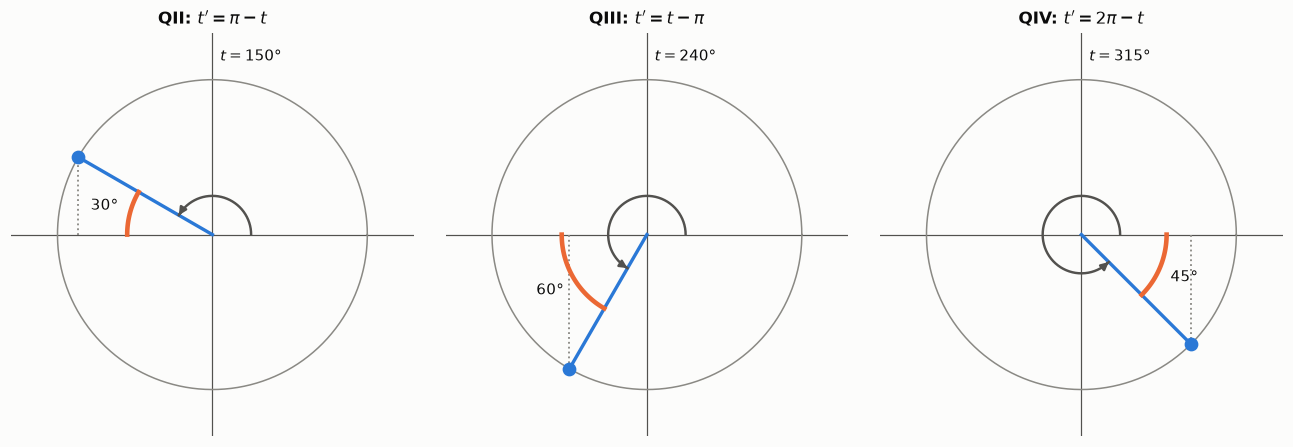

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.0))
for ax, deg, ref, title in [(axes[0], 150, 30, r"QII: $t' = \pi - t$"), (axes[1], 240, 60, r"QIII: $t' = t - \pi$"),
                            (axes[2], 315, 45, r"QIV: $t' = 2\pi - t$")]:
    bare(ax, 1.3, title)
    th = np.linspace(0, 2*np.pi, 300); ax.plot(np.cos(th), np.sin(th), color=GRAY, lw=1)
    a = np.radians(deg); c, s = np.cos(a), np.sin(a)
    ax.plot([0, c], [0, s], color=BLUE, lw=2.2); angle_arc(ax, deg, r=0.25, color=INK2)
    ax.plot([c, c], [0, s], color=GRAY, ls=":", lw=1.2)
    base = 180 if deg < 270 else 360
    t2 = np.radians(np.linspace(min(deg, base), max(deg, base), 50))
    ax.plot(0.55*np.cos(t2), 0.55*np.sin(t2), color=ORANGE, lw=3)
    mid = np.radians((deg + base)/2); ax.text(0.72*np.cos(mid), 0.72*np.sin(mid), f"{ref}°", color=INK, fontsize=10, ha="center", va="center")
    dot(ax, c, s, color=BLUE)
    ax.text(0.05, 1.12, f"$t = {deg}°$", fontsize=10)
plt.tight_layout(); plt.show()

### Sine and cosine as functions of $t$

Unwrapping the circle: as $t$ runs from $0$ to $2\pi$, $\sin t$ traces the point's height and $\cos t$ its horizontal position. Both repeat every $2\pi$ (Chapter 8 develops these graphs).

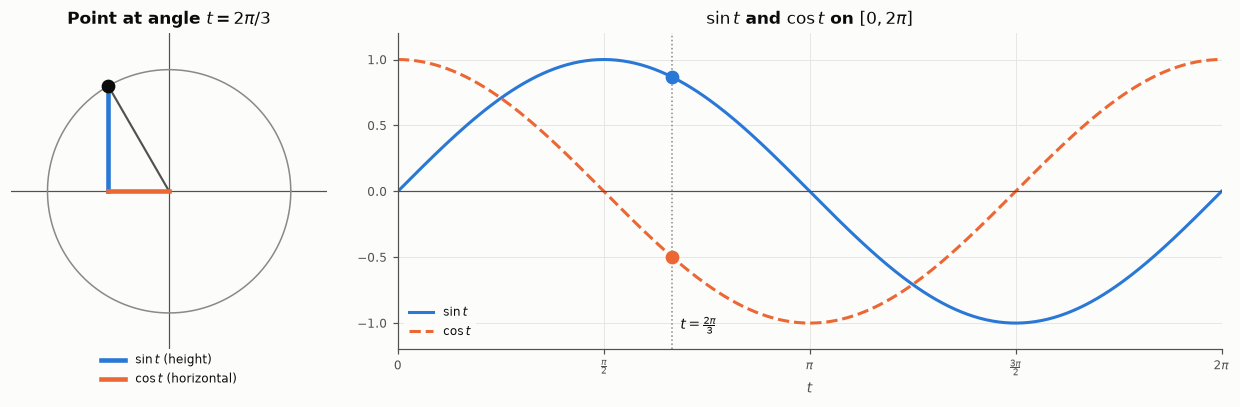

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1, 2.4]})
ax = axes[0]; bare(ax, 1.3, "Point at angle $t = 2\\pi/3$")
th = np.linspace(0, 2*np.pi, 300); ax.plot(np.cos(th), np.sin(th), color=GRAY, lw=1)
a = 2*np.pi/3; c, s = np.cos(a), np.sin(a)
ax.plot([0, c], [0, s], color=INK2, lw=1.4)
ax.plot([c, c], [0, s], color=BLUE, lw=3, label=r"$\sin t$ (height)")
ax.plot([0, c], [0, 0], color=ORANGE, lw=3, label=r"$\cos t$ (horizontal)")
dot(ax, c, s, color=INK); ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), fontsize=8)

ax = axes[1]; data_axes(ax, r"$\sin t$ and $\cos t$ on $[0, 2\pi]$", "$t$", "")
tt = np.linspace(0, 2*np.pi, 400)
ax.plot(tt, np.sin(tt), color=BLUE, label=r"$\sin t$"); ax.plot(tt, np.cos(tt), color=ORANGE, ls="--", label=r"$\cos t$")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi], ["0", r"$\frac{\pi}{2}$", r"$\pi$", r"$\frac{3\pi}{2}$", r"$2\pi$"])
dot(ax, a, s, color=BLUE); dot(ax, a, c, color=ORANGE); ax.axvline(a, color=GRAY, ls=":", lw=1)
ax.text(a + 0.06, -1.05, r"$t = \frac{2\pi}{3}$", fontsize=9)
ax.set_xlim(0, 2*np.pi); ax.set_ylim(-1.2, 1.2); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Swapping the coordinates: cosine is $x$ (first), sine is $y$ (second).
- Measuring the reference angle from the $y$-axis. It's always measured to the **$x$-axis**.
- Dropping the $\pm$ after a square root in the Pythagorean Identity, then guessing the sign. Use the quadrant.
- Writing $\sin^2 t$ as $\sin(t^2)$. $\sin^2 t$ means $(\sin t)^2$.
:::

:::{important} The book underplays this
The unit-circle definition makes sine and cosine functions of a **real number**, not just of an angle. That shift is what lets them model anything that repeats in time. Memorize the first-quadrant values cold ($\tfrac{1}{2}$, $\tfrac{\sqrt{2}}{2}$, $\tfrac{\sqrt{3}}{2}$); every other special value is one of these with a sign from the quadrant. They're good flashcard material.
:::

:::{tip} Where this shows up
**Harmonic regression:** seasonal or daily cycles are modeled by adding $\sin\left(\dfrac{2\pi t}{365}\right)$ and $\cos\left(\dfrac{2\pi t}{365}\right)$ as covariates, so the fitted curve can peak at any time of year. The **circular mean** of directions or times is found by averaging $\cos t$ and $\sin t$ separately and converting back, because averaging the angles themselves fails (the mean of $350°$ and $10°$ is $0°$, not $180°$).
:::

(sec-7-4)=
## 7.4 The Other Trigonometric Functions

### Definitions on the unit circle

For the point $(x, y)$ at angle $t$:

| Function | Definition | Undefined when |
|---|---|---|
| $\tan t$ | $\dfrac{y}{x} = \dfrac{\sin t}{\cos t}$ | $x = 0$: $t = \dfrac{\pi}{2} + k\pi$ |
| $\sec t$ | $\dfrac{1}{x} = \dfrac{1}{\cos t}$ | $x = 0$ |
| $\csc t$ | $\dfrac{1}{y} = \dfrac{1}{\sin t}$ | $y = 0$: $t = k\pi$ |
| $\cot t$ | $\dfrac{x}{y} = \dfrac{\cos t}{\sin t}$ | $y = 0$ |

$\tan t$ is the **slope** of the terminal side: the line through the origin at angle $t$ has slope $\dfrac{y}{x}$.

### Special values

| $t$ | $\sin t$ | $\cos t$ | $\tan t$ | $\csc t$ | $\sec t$ | $\cot t$ |
|---|---|---|---|---|---|---|
| $0$ | $0$ | $1$ | $0$ | undefined | $1$ | undefined |
| $\dfrac{\pi}{6}$ | $\dfrac{1}{2}$ | $\dfrac{\sqrt{3}}{2}$ | $\dfrac{\sqrt{3}}{3}$ | $2$ | $\dfrac{2\sqrt{3}}{3}$ | $\sqrt{3}$ |
| $\dfrac{\pi}{4}$ | $\dfrac{\sqrt{2}}{2}$ | $\dfrac{\sqrt{2}}{2}$ | $1$ | $\sqrt{2}$ | $\sqrt{2}$ | $1$ |
| $\dfrac{\pi}{3}$ | $\dfrac{\sqrt{3}}{2}$ | $\dfrac{1}{2}$ | $\sqrt{3}$ | $\dfrac{2\sqrt{3}}{3}$ | $2$ | $\dfrac{\sqrt{3}}{3}$ |
| $\dfrac{\pi}{2}$ | $1$ | $0$ | undefined | $1$ | undefined | $0$ |

### Identities

| Type | Identities |
|---|---|
| Reciprocal | $\csc t = \dfrac{1}{\sin t}$, $\sec t = \dfrac{1}{\cos t}$, $\cot t = \dfrac{1}{\tan t}$ |
| Quotient | $\tan t = \dfrac{\sin t}{\cos t}$, $\cot t = \dfrac{\cos t}{\sin t}$ |
| Pythagorean | $\sin^2 t + \cos^2 t = 1$, $\ 1 + \tan^2 t = \sec^2 t$, $\ 1 + \cot^2 t = \csc^2 t$ |
| Even / odd | $\cos(-t) = \cos t$, $\sec(-t) = \sec t$; sine, tangent, cosecant, cotangent are odd: $\sin(-t) = -\sin t$, etc. |
| Periodic | $\sin, \cos, \sec, \csc$ repeat every $2\pi$; $\tan, \cot$ repeat every $\pi$ |

The second and third Pythagorean identities come from dividing $\sin^2 t + \cos^2 t = 1$ by $\cos^2 t$ or by $\sin^2 t$.

**Worked example (all six from one).** $\cos t = -\tfrac{1}{3}$ with $t$ in quadrant III.

$$
\begin{aligned}
\sin t &= -\sqrt{1 - \tfrac{1}{9}} = -\frac{2\sqrt{2}}{3} \quad \text{(QIII: } y < 0\text{)} \\
\tan t &= \frac{-2\sqrt{2}/3}{-1/3} = 2\sqrt{2}, \qquad \sec t = -3 \\
\csc t &= -\frac{3}{2\sqrt{2}} = -\frac{3\sqrt{2}}{4}, \qquad \cot t = \frac{1}{2\sqrt{2}} = \frac{\sqrt{2}}{4}
\end{aligned}
$$

Check the sign pattern: in quadrant III only tangent and cotangent are positive. ✓

**Worked example (simplify).** Rewrite everything in sines and cosines:

$$
\frac{\sec t \sin t}{\tan t} = \frac{\frac{1}{\cos t} \cdot \sin t}{\frac{\sin t}{\cos t}} = \frac{\sin t}{\cos t} \cdot \frac{\cos t}{\sin t} = 1
$$

**Worked example (period and parity).** $\tan\dfrac{7\pi}{6} = \tan\left(\dfrac{\pi}{6} + \pi\right) = \tan\dfrac{\pi}{6} = \dfrac{\sqrt{3}}{3}$, and $\tan\left(-\dfrac{\pi}{3}\right) = -\tan\dfrac{\pi}{3} = -\sqrt{3}$.

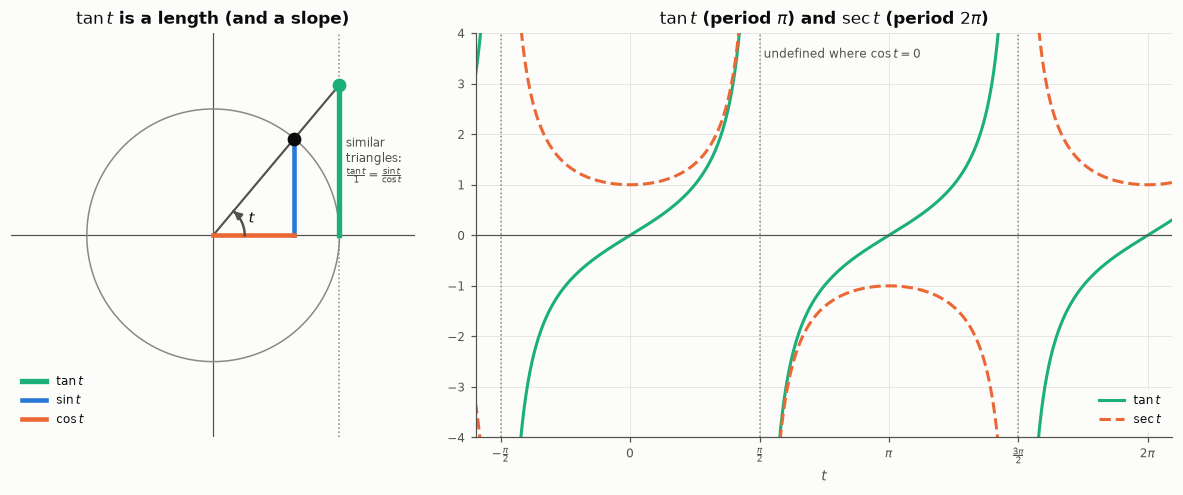

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]; bare(ax, 1.6, r"$\tan t$ is a length (and a slope)")
th = np.linspace(0, 2*np.pi, 300); ax.plot(np.cos(th), np.sin(th), color=GRAY, lw=1)
a = np.radians(50); c, s, tn = np.cos(a), np.sin(a), np.tan(a)
ax.axvline(1, color=GRAY, ls=":", lw=1)
ax.plot([0, 1], [0, tn], color=INK2, lw=1.4)
ax.plot([1, 1], [0, tn], color=AQUA, lw=3.5, label=r"$\tan t$")
ax.plot([c, c], [0, s], color=BLUE, lw=3, label=r"$\sin t$")
ax.plot([0, c], [0, 0], color=ORANGE, lw=3, label=r"$\cos t$")
dot(ax, c, s, color=INK); dot(ax, 1, tn, color=AQUA)
angle_arc(ax, 50, r=0.25, color=INK2); ax.text(0.28, 0.1, "$t$", fontsize=10)
ax.legend(loc="lower left", fontsize=8)
ax.text(1.05, tn/2, "similar\ntriangles:\n" + r"$\frac{\tan t}{1} = \frac{\sin t}{\cos t}$", fontsize=8, color=INK2, va="center")

ax = axes[1]; data_axes(ax, r"$\tan t$ (period $\pi$) and $\sec t$ (period $2\pi$)", "$t$", "")
for k in range(-1, 3):
    lo, hi = -np.pi/2 + k*np.pi + 0.02, np.pi/2 + k*np.pi - 0.02
    tt = np.linspace(lo, hi, 300)
    ax.plot(tt, clip(np.tan(tt), 4.2), color=AQUA, label=r"$\tan t$" if k == 0 else None)
    ax.plot(tt, clip(1/np.cos(tt), 4.2), color=ORANGE, ls="--", label=r"$\sec t$" if k == 0 else None)
    ax.axvline(np.pi/2 + k*np.pi, color=GRAY, ls=":", lw=1)
ax.axhline(0, color=INK2, lw=0.8)
ticks = [-np.pi/2, 0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi]
ax.set_xticks(ticks, [r"$-\frac{\pi}{2}$", "0", r"$\frac{\pi}{2}$", r"$\pi$", r"$\frac{3\pi}{2}$", r"$2\pi$"])
ax.set_xlim(-np.pi/2 - 0.3, 2*np.pi + 0.3); ax.set_ylim(-4, 4); ax.legend(loc="lower right", fontsize=8)
ax.text(np.pi/2 + 0.05, 3.5, "undefined where $\\cos t = 0$", fontsize=8, color=INK2)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Writing $\sec t = \dfrac{1}{\sin t}$. Pair them by the letters that *don't* match: **s**ec goes with **c**os, **c**sc goes with **s**in.
- Calling $\tan\dfrac{\pi}{2} = \infty$ or $0$. It's **undefined** ($x = 0$).
- Using $2\pi$ as the period of tangent. Tangent repeats every $\pi$.
- Taking $\sin^{-1}$ on a calculator for $\csc$. $\sin^{-1}$ is the inverse function (Chapter 8), not the reciprocal. Use $1/\sin$.
- Losing signs when finding all six from one value. Fix the signs of $\sin$ and $\cos$ from the quadrant first; the other four follow.
:::

:::{important} The book underplays this
$\tan t$ is the **slope** of the terminal side. That connects trig directly to Chapter 4: a line with angle of inclination $\theta$ has slope $m = \tan\theta$, and a 10% road grade is an angle of $\theta$ with $\tan\theta = 0.10$ (about $5.7°$). In Stewart, $\dfrac{d}{dt}\tan t = \sec^2 t$, which is why the identity $1 + \tan^2 t = \sec^2 t$ matters.
:::

:::{tip} Where this shows up
In GIS, terrain **slope** from a DEM is $\arctan\left(\dfrac{\text{rise}}{\text{run}}\right)$, and **aspect** is a compass angle. Because aspect is circular ($359°$ and $1°$ are neighbors), habitat models enter it as $\cos(\text{aspect})$ ("northness") and $\sin(\text{aspect})$ ("eastness") rather than as a raw angle.
:::

## Exercises to prioritize

Odd numbers have answers in the back. This chapter is more memorization than algebra: aim to know the unit circle without looking before moving on.

| Section | Core set | Notes |
|---|---|---|
| 7.1 | Graphical 7–21 odd; Algebraic 27–57 odd; Real-World 59–67 odd | Includes arc length, sector area, and angular/linear speed problems. |
| 7.2 | Algebraic 7–15 odd; Graphical 17–31 odd; Extensions 43–51 odd; Real-World 53, 55 | Extensions are the height and distance word problems. |
| 7.3 | Algebraic 7–21 odd; Numeric 23–59 odd; Graphical 61–79 odd; Extensions 91–97 odd | Numeric 23–59 (reference angles, exact values, Pythagorean Identity) is the core of the chapter. |
| 7.4 | Algebraic 7–47 odd; Graphical 49; Extensions 63–71 odd | Extensions 63–71 are the identity problems; they preview Chapter 9. |

**Cold diagnostic.** A few days after the section work, do the **Practice Test** (1–23), timed and with no notes or calculator for exact values. The **Review Exercises** (1–50, grouped by section) are the follow-up.